## 第2章「顧客を分類する」— サポートページ共通セットアップ

サポートページ全体で使用するパスの設定、DataFrame 表示スタイルの適用、および `matplotlib_fontja` のインポートを行う。


In [1]:
import sys
from pathlib import Path

import matplotlib_fontja  # noqa: F401

for path in [Path.cwd(), *Path.cwd().parents]:
    if (path / "common" / "notebook_style.py").exists():
        sys.path.insert(0, str(path))
        break

    if (path / "src" / "common" / "notebook_style.py").exists():
        sys.path.insert(0, str(path / "src"))
        break

from common.notebook_style import apply_dataframe_style, get_data_path

apply_dataframe_style()

# 第2章 顧客を分類する


## 第2章、第3節、第1項のコード

### データの読み込みと特徴量の作成

UCI Online Retail データセット（`online_retail.csv.gz`）を Polars で読み込み、顧客 ID ごとに集計した分析用データを作成する。UCI の説明では多くの顧客が卸売業者であるため、高支出・高頻度の成分を一般消費者の「継続して利用する重要顧客」とすぐに判断しない。

出典: Daqing Chen, [Online Retail](https://doi.org/10.24432/C5BW33), UCI Machine Learning Repository, 2015。ライセンス: [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/)。元データをCSV形式に変換し、以下の加工を行う。

#### 処理内容

1. **ライブラリのインポート**
   `polars`, `numpy`, `StandardScaler`, `matplotlib`, `matplotlib_fontja` をインポートする。

2. **CSV ファイルの読み込みと観測期間の確認**
   `get_data_path("online_retail.csv.gz")` で実行場所に依存せずファイルを解決し、`pl.read_csv()` で読み込む。列のデータ型を判断するために確認する行数を 10,000 行に設定し、日付を自動で日付形式として読み込む。最小・最大の請求日時を取得し、観測の開始日・終了日を明示する。顧客ごとの最低観測期間は設けず、観測開始時点の既存顧客か期間途中の新規顧客かも区別しないため、注文回数をそのまま離反や定着の指標とはみなさない。

3. **条件ごとの除外件数の記録**
   `CustomerID` 欠損、`Quantity <= 0`、`UnitPrice <= 0` をこの順に除外し、各段階の除外行数と残った行数を `preprocessing_counts` に記録する。

4. **キャンセル・返品・重複している可能性のある行の扱い**
   キャンセル・返品を表す数量が 0 以下の行は除外するが、対応する元の購入明細との対応づけは行わない。このため `total_expenditure` は返品分を差し引いた金額ではなく、数量が正の購入明細だけの合計である。全列が同じ行は件数を記録するが、正しい重複かを判断できないため本例では除外しない。

5. **顧客ごとの集計と極端な値の影響を小さくする処理**
   `group_by("CustomerID")` で総支出額・注文回数・購入商品の種類数・購入数量・国を集計する。総支出額と注文回数の両方に `log1p` を適用し、少数の極端な顧客が距離の計算に強く影響することを抑える。顧客自体は除外しない。

6. **処理件数・観測条件・先頭データの確認**
   `preprocessing_counts`、`observation_definition`、`df.head()` を表示し、分析対象の定義とデータ構造を確認する。


In [3]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from matplotlib.colors import LinearSegmentedColormap
from sklearn.preprocessing import StandardScaler

# 1色印刷用のグレースケール設定
MONO_BLACK = "0.00"
MONO_DARK = "0.25"
MONO_MID = "0.55"
MONO_LIGHT = "0.82"

# クラスタは濃淡だけでなくマーカー形状でも区別する
CLUSTER_STYLES = [
    {"color": "0.10", "marker": "o"},
    {"color": "0.35", "marker": "s"},
    {"color": "0.60", "marker": "^"},
    {"color": "0.82", "marker": "D"},
]

# 確率0を薄い灰色、確率1を黒で表示する
PROBABILITY_CMAP = LinearSegmentedColormap.from_list(
    "probability_gray", [MONO_LIGHT, MONO_BLACK]
)


# データ読み込み
data_path = get_data_path("online_retail.csv.gz")
raw_retail_df = pl.read_csv(
    data_path,
    infer_schema_length=10000,
    try_parse_dates=True,
)

observation_start = raw_retail_df["InvoiceDate"].min()
observation_end = raw_retail_df["InvoiceDate"].max()
observation_definition = pl.DataFrame(
    {
        "item": [
            "観測の開始日時",
            "観測の終了日時",
            "顧客ごとの最低観測期間",
            "顧客ごとの観測期間の補正",
        ],
        "definition": [
            str(observation_start),
            str(observation_end),
            "設定しない",
            "行わない",
        ],
    }
)

# 除外条件を順番に適用し、各段階の件数を記録
customer_identified_df = raw_retail_df.filter(
    pl.col("CustomerID").is_not_null()
)
positive_quantity_df = customer_identified_df.filter(pl.col("Quantity") > 0)
retail_df = positive_quantity_df.filter(pl.col("UnitPrice") > 0).with_columns(
    (pl.col("Quantity") * pl.col("UnitPrice")).alias("line_amount")
)

# 全列が同じ行を、重複している可能性のある行として数える（本例では除外しない）
raw_duplicate_candidates = raw_retail_df.height - raw_retail_df.unique().height
analysis_duplicate_candidates = retail_df.height - retail_df.unique().height

# 1行1顧客の分析用データに集計
df = (
    retail_df.group_by("CustomerID")
    .agg(
        pl.col("line_amount").sum().alias("total_expenditure"),
        pl.col("InvoiceNo").n_unique().alias("order_count"),
    )
    .with_columns(
        pl.col("total_expenditure").log1p().alias("total_expenditure_log"),
        pl.col("order_count").cast(pl.Float64).log1p().alias("order_count_log"),
    )
    .sort("CustomerID")
)

preprocessing_counts = pl.DataFrame(
    {
        "step": [
            "読み込み",
            "CustomerID 欠損を除外",
            "Quantity <= 0 を除外",
            "UnitPrice <= 0 を除外",
            "CustomerID 単位に集計",
        ],
        "excluded": [
            None,
            raw_retail_df.height - customer_identified_df.height,
            customer_identified_df.height - positive_quantity_df.height,
            positive_quantity_df.height - retail_df.height,
            None,
        ],
        "remaining": [
            raw_retail_df.height,
            customer_identified_df.height,
            positive_quantity_df.height,
            retail_df.height,
            df.height,
        ],
        "unit": ["行", "行", "行", "行", "顧客"],
    }
)
display(preprocessing_counts)
display(observation_definition)
print(
    f"全列が同じ行: 生データ {raw_duplicate_candidates:,} 行、"
    f"分析対象明細 {analysis_duplicate_candidates:,} 行（本例では除外しない）"
)

df.head()

step,excluded,remaining,unit
str,i64,i64,str
"""読み込み""",null,541909,"""行"""
"""CustomerID 欠損を除外""",135080,406829,"""行"""
"""Quantity <= 0 を除外""",8905,397924,"""行"""
"""UnitPrice <= 0 を除外""",40,397884,"""行"""
"""CustomerID 単位に集計""",null,4338,"""顧客"""


item,definition
str,str
"""観測の開始日時""","""2010-12-01 08:26:00"""
"""観測の終了日時""","""2011-12-09 12:50:00"""
"""顧客ごとの最低観測期間""","""設定しない"""
"""顧客ごとの観測期間の補正""","""行わない"""


全列が同じ行: 生データ 5,268 行、分析対象明細 5,192 行（本例では除外しない）


CustomerID,total_expenditure,order_count,total_expenditure_log,order_count_log
i64,f64,u32,f64,f64
12346,77183.6,1,11.253955,0.693147
12347,4310.0,7,8.368925,2.079442
12348,1797.24,4,7.494564,1.609438
12349,1757.55,1,7.472245,0.693147
12350,334.4,1,5.815324,0.693147


## 第2章、第3節、第1項のコード

### 特徴量の作成と標準化

顧客ごとに集計した総支出額と注文回数をそれぞれ `log1p` 変換した 2 つの特徴量を取り出し、`StandardScaler` で平均 0・分散 1 になるよう標準化する。対数変換後の値はクラスタリングの計算に使い、結果の説明には元の単位の金額と回数を使う。総支出額はおおむね「注文回数 × 1 注文当たり金額」なので、2 軸は独立ではない。本章では、同じ総支出額でも大口の単発購入と複数回の購入を分けて見るため、重なりを承知したうえで両方を使う。結果は独立した 2 要因ではなく、総合的な購買規模の段階として解釈する。1 回の注文でどのくらい購入しているかを見たい場合は、総支出額の代わりに平均注文額を使った結果も比較する。

#### 処理内容

1. **特徴量の抽出**
   `df.select(["total_expenditure_log", "order_count_log"])` で 2 列を取り出す。

2. **標準化**
   `StandardScaler().fit_transform()` で各特徴量を平均0・分散1に変換する。

3. **標準化した値をまとめた DataFrame の作成**
   変換後の numpy 配列を Polars DataFrame に変換し、`df_scaled` として保持する。

4. **構造と標準化結果の確認**
   `df_scaled.head()` で 2 列の構造を確認する。さらに全顧客について列ごとの平均と分散（`ddof=0`）を計算し、平均 0・分散 1 になっていることを `scaling_check` で確認する。


In [5]:
# 外れ値の影響を緩和した特徴量を抽出
features = df.select(["total_expenditure_log", "order_count_log"])

# 標準化
scaler = StandardScaler()
scaled_values = scaler.fit_transform(features.to_numpy())

df_scaled = pl.DataFrame(
    scaled_values,
    schema=["total_expenditure_log_scaled", "order_count_log_scaled"],
)

X = df_scaled.to_numpy()

scaling_check = pl.DataFrame(
    {
        "feature": df_scaled.columns,
        "mean": [float(df_scaled[c].mean()) for c in df_scaled.columns],
        "population_variance": [
            float(df_scaled[c].var(ddof=0)) for c in df_scaled.columns
        ],
    }
)
display(scaling_check)

df_scaled.head()

feature,mean,population_variance
str,f64,f64
"""total_expenditure_log_scaled""",2.9811e-16,1.0
"""order_count_log_scaled""",-9.4182e-18,1.0


total_expenditure_log_scaled,order_count_log_scaled
f64,f64
3.706225,-0.955214
1.411843,1.074425
0.716489,0.386304
0.698739,-0.955214
-0.618962,-0.955214


## 第2章、第3節、第1項のコード

### 極端に大きい値への対応方法の比較

現行の処理、総支出額の上位 0.5% を上限値に置き換える処理、両軸の対数変換を比較する。各条件で $K=4$ の k-means を実行し、各クラスタの顧客数、グループ内のまとまりとグループ間の離れ具合を表すシルエット係数、初期値に対する安定性を確認する。

#### 処理内容

1. **前処理候補の作成**
   現行処理、99.5% 上限処理、両軸対数変換の 3 条件を作成する。

2. **同一条件での比較**
   各条件を標準化し、`n_init=20` の k-means を実行する。

3. **診断指標の計算**
   シルエット係数、各クラスタの最小・最大顧客数、10 通りの乱数の設定で得た分類結果の最小 ARI を計算する。ARI は分類結果どうしの一致度を表す。

   各クラスタの顧客数も凡例に記載する。


preprocessing,silhouette_k4,minimum_segment_size,maximum_segment_size,minimum_seed_ari
str,f64,i64,i64,f64
"""現行：総支出額＋対数頻度""",0.6178,7,2326,0.994
"""99.5%上限処理＋対数頻度""",0.593,38,2324,1.0
"""採用案：両軸を対数変換""",0.4233,336,1514,0.9776


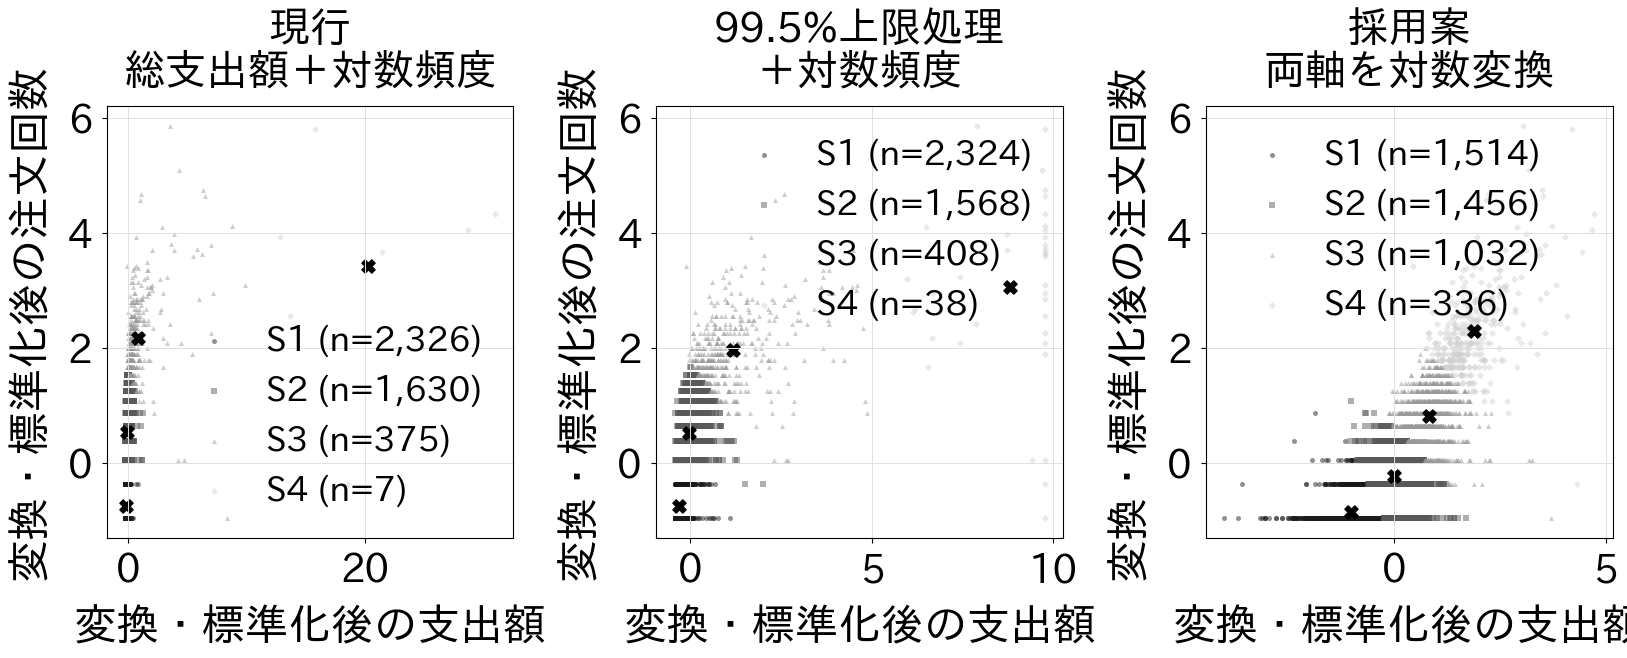

In [7]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

expenditure = df["total_expenditure"].to_numpy().astype(float)
frequency = df["order_count"].to_numpy().astype(float)

preprocessing_options = {
    "現行：総支出額＋対数頻度": np.column_stack(
        [expenditure, np.log1p(frequency)]
    ),
    "99.5%上限処理＋対数頻度": np.column_stack(
        [
            np.minimum(expenditure, np.quantile(expenditure, 0.995)),
            np.log1p(frequency),
        ]
    ),
    "採用案：両軸を対数変換": np.column_stack(
        [np.log1p(expenditure), np.log1p(frequency)]
    ),
}

comparison_rows = []
comparison_results = []
for name, transformed in preprocessing_options.items():
    option_scaler = StandardScaler()
    X_option = option_scaler.fit_transform(transformed)
    model = KMeans(n_clusters=4, random_state=42, n_init=20).fit(X_option)

    centers_original = option_scaler.inverse_transform(model.cluster_centers_)
    order = np.argsort(centers_original.sum(axis=1))
    mapping = np.empty_like(order)
    mapping[order] = np.arange(4)
    labels_option = mapping[model.labels_]
    centers_option = model.cluster_centers_[order]

    seed_labels = [
        KMeans(n_clusters=4, random_state=seed, n_init=20).fit_predict(X_option)
        for seed in range(10)
    ]
    stability = min(
        adjusted_rand_score(seed_labels[0], other) for other in seed_labels[1:]
    )
    counts = np.bincount(labels_option)
    comparison_rows.append(
        {
            "preprocessing": name,
            "silhouette_k4": round(
                silhouette_score(X_option, labels_option), 4
            ),
            "minimum_segment_size": int(counts.min()),
            "maximum_segment_size": int(counts.max()),
            "minimum_seed_ari": round(stability, 4),
        }
    )
    comparison_results.append((name, X_option, labels_option, centers_option))

preprocessing_comparison = pl.DataFrame(comparison_rows)
display(preprocessing_comparison)

fig, axes = plt.subplots(1, 3, figsize=(16.5, 6.8))
for ax, (name, X_option, labels_option, centers_option) in zip(
    axes, comparison_results
):
    for segment in range(4):
        mask = labels_option == segment
        style = CLUSTER_STYLES[segment]
        ax.scatter(
            X_option[mask, 0],
            X_option[mask, 1],
            color=style["color"],
            marker=style["marker"],
            s=13,
            alpha=0.48,
            linewidths=0,
            label=f"S{segment + 1} (n={mask.sum():,})",
        )
    ax.scatter(
        centers_option[:, 0],
        centers_option[:, 1],
        color=MONO_BLACK,
        marker="X",
        s=90,
    )
    title_lines = {
        "現行：総支出額＋対数頻度": "現行\n総支出額＋対数頻度",
        "99.5%上限処理＋対数頻度": "99.5%上限処理\n＋対数頻度",
        "採用案：両軸を対数変換": "採用案\n両軸を対数変換",
    }
    ax.set_title(title_lines[name], fontsize=30, pad=16, linespacing=1.08)
    ax.set_xlabel("変換・標準化後の支出額", fontsize=31, labelpad=12)
    ax.set_ylabel("変換・標準化後の注文回数", fontsize=31, labelpad=12)
    ax.tick_params(axis="both", labelsize=28, pad=7)
    ax.grid(True, color="0.88", linewidth=0.7)
    ax.legend(fontsize=25, frameon=False, handletextpad=0.5)

fig.tight_layout(pad=1.5, w_pad=2.2)
plt.show()

## 第2章、第3節、第2項のコード

### エルボー法の実装例

$K=1,\ldots,10$ の各モデルについて k-means の `inertia_`（SSE）を記録し、SSE の低下が全体として鈍くなる形を折れ線グラフで確認する。最小の SSE は $K$ を増やしても大きくならないが、隣り合う $K$ の改善幅が毎回小さくなるとは限らない。

#### 処理内容

1. **KMeans の繰り返し実行**
   $K = 1$ から $10$ まで `KMeans` を実行し、各 $K$ の `inertia_`（SSE）を `SSE` リストに追加する。

2. **エルボーグラフの描画**
   横軸にクラスタの数 $K$、縦軸に SSE をとった折れ線グラフを描き、SSE の減少が鈍くなる「肘」の位置を確認する。


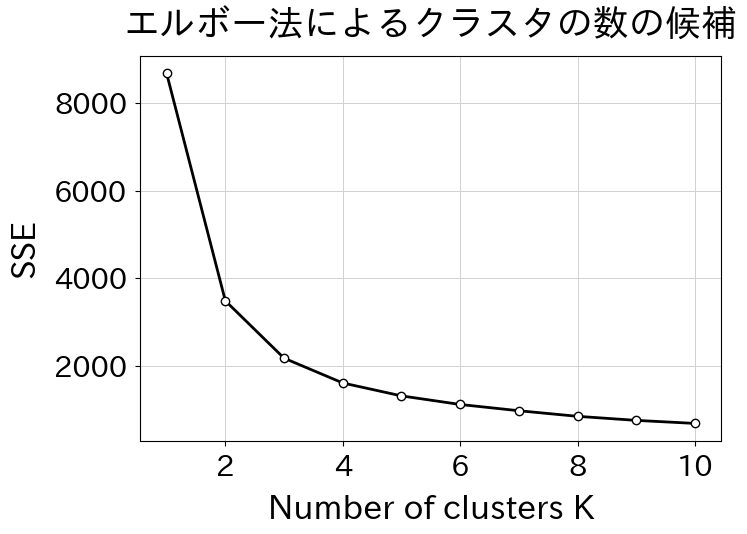

In [8]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

X = df_scaled.to_numpy()

SSE = []
K_range = range(1, 11)

for K in K_range:
    km = KMeans(n_clusters=K, random_state=42, n_init=20)
    km.fit(X)
    SSE.append(km.inertia_)

fig = plt.figure(figsize=(7.5, 5.0))
plt.plot(
    K_range,
    SSE,
    color=MONO_BLACK,
    linewidth=2,
    marker="o",
    markerfacecolor="white",
    markeredgecolor=MONO_BLACK,
)
plt.xlabel("Number of clusters K", fontsize=24, labelpad=10)
plt.ylabel("SSE", fontsize=24, labelpad=10)
plt.title("エルボー法によるクラスタの数の候補", fontsize=26, pad=14)
plt.tick_params(labelsize=21, pad=6)
plt.grid(True, color=MONO_LIGHT, linewidth=0.7)
plt.show()

## 第2章、第3節、第3項のコード

### k-means による学習の実行

両軸を対数変換して標準化した特徴量に対して $K=4$ の k-means を実行する。クラスタの番号は初期値により入れ替わるため、重心が左下から右上へ並ぶ順にセグメント 1～4 を付け直し、元の単位の中央値と四分位範囲（第 1 四分位数～第 3 四分位数）も計算する。

#### 処理内容

1. **k-means の実行**
   `KMeans(n_clusters=4, random_state=42, n_init=20)` を使い、複数の初期値から最良の解を選ぶ。

2. **クラスタの番号の並べ替え**
   対数変換後の重心が左下から右上へ並ぶ順に、セグメントの番号を 1～4 として付け直す。

3. **元の単位での特徴の確認**
   各セグメントについて、顧客数、総支出額と注文回数の中央値・第 1 四分位数・第 3 四分位数を計算する。


In [9]:
from sklearn.cluster import KMeans

X = df_scaled.to_numpy()

kmeans = KMeans(n_clusters=4, random_state=42, n_init=20)
raw_labels = kmeans.fit_predict(X)
centers_log = scaler.inverse_transform(kmeans.cluster_centers_)

# 重心が左下から右上へ並ぶ順に、セグメント番号を固定する
kmeans_order = np.argsort(centers_log.sum(axis=1))
kmeans_mapping = np.empty_like(kmeans_order)
kmeans_mapping[kmeans_order] = np.arange(4)
labels = kmeans_mapping[raw_labels]
centers = kmeans.cluster_centers_[kmeans_order]

kmeans_profile = (
    df.with_columns(pl.Series("segment", labels + 1))
    .group_by("segment")
    .agg(
        pl.len().alias("customers"),
        pl.col("total_expenditure")
        .median()
        .round(2)
        .alias("expenditure_median_gbp"),
        pl.col("total_expenditure")
        .quantile(0.25)
        .round(2)
        .alias("expenditure_q1_gbp"),
        pl.col("total_expenditure")
        .quantile(0.75)
        .round(2)
        .alias("expenditure_q3_gbp"),
        pl.col("order_count").median().alias("orders_median"),
        pl.col("order_count").quantile(0.25).alias("orders_q1"),
        pl.col("order_count").quantile(0.75).alias("orders_q3"),
    )
    .sort("segment")
)

# 計算用の列名は保ち、表示用の表だけ短い日本語へ変更する
kmeans_profile_display = kmeans_profile.to_pandas().rename(
    columns={
        "segment": "Seg.",
        "customers": "顧客数",
        "expenditure_median_gbp": "支出中央値",
        "expenditure_q1_gbp": "支出Q1",
        "expenditure_q3_gbp": "支出Q3",
        "orders_median": "注文中央値",
        "orders_q1": "注文Q1",
        "orders_q3": "注文Q3",
    }
)


kmeans_profile_display

,Seg.,顧客数,支出中央値,支出Q1,支出Q3,注文中央値,注文Q1,注文Q3
0,1,1514,223.86,146.85,320.58,1.0,1.0,1.0
1,2,1456,707.96,550.80,996.26,2.0,2.0,3.0
2,3,1032,2043.40,1445.01,2863.08,6.0,4.0,7.0
3,4,336,6413.67,4448.54,10674.75,15.0,12.0,21.0


## 第2章、第3節、第3項のコード

### k-means による分類の結果の可視化

得られたクラスタの番号と重心を使い、顧客の分布を散布図で示す。極端な値を隠さない全体図と、点を削除せず各軸の 0.5～99.5 パーセンタイルだけを表示する中央 99% 拡大図を並べる。凡例には実際の顧客数も記載する。

#### 処理内容

1. **全体図と中央領域の拡大図**
   各セグメントを濃淡とマーカー形状で区別し、クラスタの中心を黒の `X` 印で表示する。右図は表示範囲だけを狭め、学習対象は全顧客のままとする。


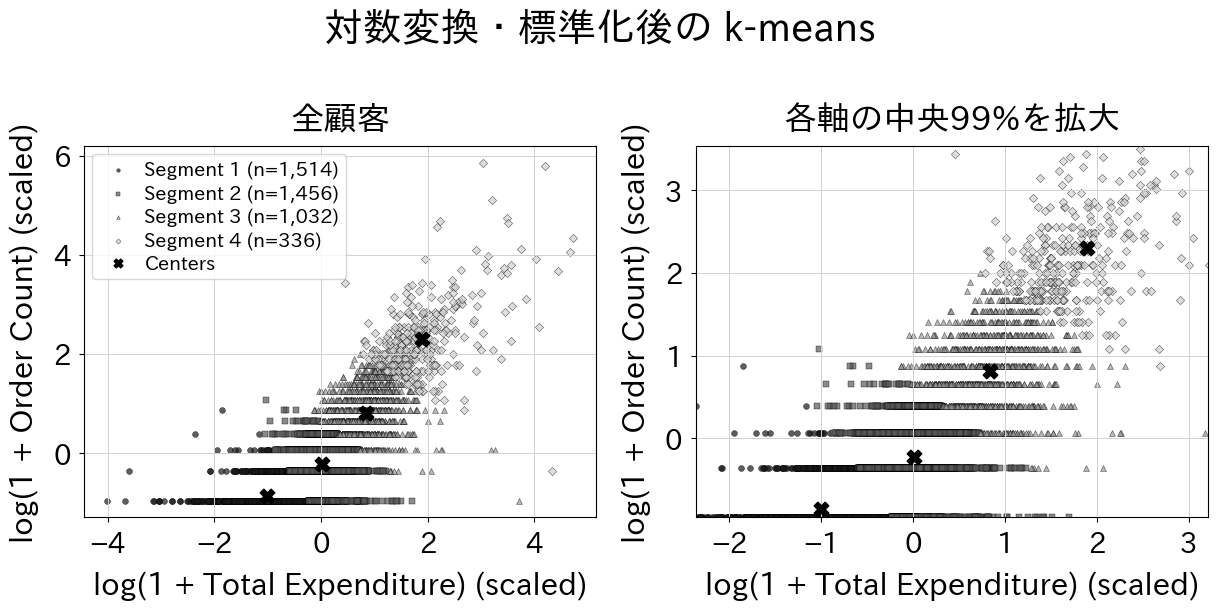

In [10]:
central_limits = np.quantile(X, [0.005, 0.995], axis=0)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 6.2))

for panel, (ax, title) in enumerate(
    zip(axes, ["全顧客", "各軸の中央99%を拡大"])
):
    for k in range(4):
        style = CLUSTER_STYLES[k]
        ax.scatter(
            X[labels == k, 0],
            X[labels == k, 1],
            color=style["color"],
            marker=style["marker"],
            edgecolors=MONO_BLACK,
            linewidths=0.35,
            alpha=0.70,
            s=18,
            label=f"Segment {k + 1} (n={(labels == k).sum():,})",
        )
    ax.scatter(
        centers[:, 0],
        centers[:, 1],
        color=MONO_BLACK,
        marker="X",
        s=110,
        label="Centers",
        zorder=5,
    )
    if panel == 1:
        ax.set_xlim(*central_limits[:, 0])
        ax.set_ylim(*central_limits[:, 1])
    ax.set_xlabel(
        "log(1 + Total Expenditure) (scaled)", fontsize=22, labelpad=10
    )
    ax.set_ylabel("log(1 + Order Count) (scaled)", fontsize=22, labelpad=10)
    ax.set_title(title, fontsize=24, pad=12)
    ax.tick_params(axis="both", labelsize=20, pad=6)
    ax.grid(True, color=MONO_LIGHT, linewidth=0.7)

axes[0].legend(
    fontsize=14,
    loc="upper left",
    frameon=True,
    markerscale=0.6,
    borderpad=0.35,
    labelspacing=0.25,
    handletextpad=0.35,
    borderaxespad=0.4,
)
fig.suptitle("対数変換・標準化後の k-means", fontsize=28)
fig.tight_layout(rect=[0, 0, 1, 0.94], pad=1.2, w_pad=1.8)
plt.show()

## 第2章、第4節、第1項のコード

### GMM の成分の数・共分散の設定の比較と学習

scikit-learn の `GaussianMixture` クラスを使い、まず成分の数 $K=1,\ldots,8$ と共分散の設定 `full` と `diag` を AIC と BIC で比較する。そのうえで、k-means との比較と 4 段階の施策の設計を優先し、最終モデルは $K=4$、`full` とする。情報量規準が選ぶ値と実務上採用する値は区別する。成分の番号は平均が左下から右上へ並ぶ順に 1～4 として固定する。

#### AIC と BIC とは

成分の数を増やすと、GMM は複雑な分布にも合わせやすくなる一方、必要以上に細かな成分へ分割する可能性がある。AIC（Akaike Information Criterion：赤池情報量規準）と BIC（Bayesian Information Criterion：ベイズ情報量規準）は、データへの当てはまりとモデルの複雑さを同時に評価するための指標である。

$$
\mathrm{AIC}=-2\log L+2p, \qquad
\mathrm{BIC}=-2\log L+p\log n.
$$

ここで、$L$ は学習後のモデルがデータにどの程度よく当てはまるかを表す値、$p$ はモデルで求める値の数、$n$ は顧客数である。$-2\log L$ の部分は当てはまりの悪さ、その後の項はモデルの複雑さに応じて加える値と考えるとよい。したがって、AIC と BIC はいずれも、比較した候補の中で値が小さいモデルをよい候補と判断する。値そのものに単独の意味はなく、同じデータに当てはめた候補同士で比較する。

AIC は比較的データへの当てはまりを重視し、BIC は顧客数 $n$ が大きいと複雑なモデルをより選びにくくする。このため両者が異なる成分の数を選ぶこともある。

#### この結果の読み方

今回の比較では、AIC と BIC はどちらも、調べた範囲の上限である $K=8$ まで低下している。これは「真の顧客グループが 8 個」と確定したことではなく、$K=1,\ldots,8$ の範囲では明確な最小点が得られなかったことを意味する。本章では、情報量規準だけで成分の数を決めず、k-means と同じ条件で比較できること、セグメントを 4 段階の施策として説明できることを優先して $K=4$ を採用する。

#### 処理内容

1. **成分の数と共分散の設定の比較**
   $K=1,\ldots,8$、`covariance_type="full"` と `"diag"` の各候補を `n_init=10` で学習し、AIC と BIC を比較する。

2. **最終 GMM の学習**
   比較目的を明示したうえで $K=4$ とし、`covariance_type="full"`, `n_init=20`, `reg_covar=1e-3` を指定して各成分の共分散行列を個別に推定する。

3. **所属確率と割り当て先の取得**
   `gmm.predict_proba(X)` で所属確率を取得し、もっとも確率が高い成分を割り当て先とする。

4. **成分番号の並べ替えと特徴確認**
   成分の中心となる平均値を左下から右上へ並べ、顧客数、元の単位の中央値・四分位範囲、もっとも高い所属確率の中央値を確認する。

5. **共分散の診断**
   成分が全体に占める割合、2 軸の標準偏差、相関係数を確認し、共分散の計算が不安定になっていないかも調べる。注文回数は整数なので、特定回数の水平帯に集中する成分では縦方向の分散が極端に小さくなりうる。


covariance_type,bic_best_k,minimum_bic,aic_best_k,minimum_aic
str,i64,f64,i64,f64
"""diag""",8,6362.8,8,6114.2
"""full""",8,7247.1,8,6947.5


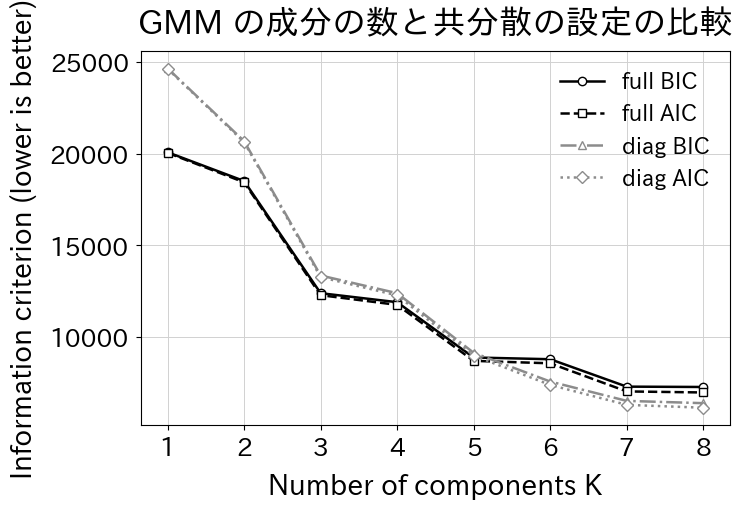

component,customers,expenditure_median_gbp,expenditure_q1_gbp,expenditure_q3_gbp,orders_median,orders_q1,orders_q3,max_probability_median
i64,u32,f64,f64,f64,f64,f64,f64,f64
1,1492,257.51,153.9,406.09,1.0,1.0,1.0,0.998
2,1343,632.0,383.68,992.5,2.0,2.0,3.0,0.873
3,1297,1906.09,1197.81,3046.21,6.0,4.0,8.0,0.887
4,206,10225.38,6316.57,17220.36,20.0,12.0,28.0,0.882


component,mixture_weight,expenditure_sd_scaled,orders_sd_scaled,correlation,minimum_eigenvalue
i64,f64,f64,f64,f64,f64
1,0.343,0.642,0.032,-0.0,0.001
2,0.288,0.596,0.261,0.332,0.0591
3,0.297,0.558,0.614,0.711,0.0986
4,0.072,1.048,1.218,0.578,0.5283


metric,value
str,f64
"""converged""",1.0
"""iterations""",14.0
"""median_max_probability""",0.944099
"""share_max_probability_below_0_…",0.20816


In [11]:
from matplotlib.patches import Ellipse
from sklearn.mixture import GaussianMixture

X = df_scaled.to_numpy()

# 成分の数と共分散の設定を AIC と BIC で比較
model_selection_rows = []
for covariance_type in ["full", "diag"]:
    for components in range(1, 9):
        candidate = GaussianMixture(
            n_components=components,
            covariance_type=covariance_type,
            random_state=42,
            n_init=10,
            reg_covar=1e-3,
        ).fit(X)
        model_selection_rows.append(
            {
                "covariance_type": covariance_type,
                "components": components,
                "bic": candidate.bic(X),
                "aic": candidate.aic(X),
                "converged": candidate.converged_,
            }
        )

gmm_model_selection = pl.DataFrame(model_selection_rows)
gmm_model_selection_summary = (
    gmm_model_selection.group_by("covariance_type")
    .agg(
        pl.col("components").sort_by("bic").first().alias("bic_best_k"),
        pl.col("bic").min().round(1).alias("minimum_bic"),
        pl.col("components").sort_by("aic").first().alias("aic_best_k"),
        pl.col("aic").min().round(1).alias("minimum_aic"),
    )
    .sort("covariance_type")
)
display(gmm_model_selection_summary)

fig, ax = plt.subplots(figsize=(7.5, 5.2))
criterion_styles = {
    ("full", "bic"): (MONO_BLACK, "o", "-"),
    ("full", "aic"): (MONO_BLACK, "s", "--"),
    ("diag", "bic"): (MONO_MID, "^", "-."),
    ("diag", "aic"): (MONO_MID, "D", ":"),
}
for covariance_type in ["full", "diag"]:
    subset = gmm_model_selection.filter(
        pl.col("covariance_type") == covariance_type
    ).sort("components")
    for criterion in ["bic", "aic"]:
        color, marker, linestyle = criterion_styles[
            (covariance_type, criterion)
        ]
        ax.plot(
            subset["components"],
            subset[criterion],
            color=color,
            marker=marker,
            linestyle=linestyle,
            linewidth=1.8,
            markerfacecolor="white",
            label=f"{covariance_type} {criterion.upper()}",
        )
ax.set_xlabel("Number of components K", fontsize=20, labelpad=9)
ax.set_ylabel(
    "Information criterion (lower is better)", fontsize=20, labelpad=9
)
ax.set_title("GMM の成分の数と共分散の設定の比較", fontsize=24, pad=13)
ax.set_xticks(range(1, 9))
ax.tick_params(axis="both", labelsize=18, pad=5)
ax.grid(True, color=MONO_LIGHT, linewidth=0.7)
ax.legend(frameon=False, fontsize=16)
fig.tight_layout()
plt.show()

K = 4  # k-means と比較し、施策上の4段階として読むため固定
gmm = GaussianMixture(
    n_components=K,
    covariance_type="full",
    random_state=42,
    n_init=20,
    reg_covar=1e-3,
)
gmm.fit(X)

# 所属確率を求め、平均が左下から右上へ並ぶ順に成分番号を固定する
raw_proba = gmm.predict_proba(X)
means_log = scaler.inverse_transform(gmm.means_)
gmm_order = np.argsort(means_log.sum(axis=1))
proba = raw_proba[:, gmm_order]
labels_gmm = np.argmax(proba, axis=1)
gmm_component = labels_gmm + 1
centers_gmm = gmm.means_[gmm_order]
gmm_covariances = gmm.covariances_[gmm_order]
gmm_weights = gmm.weights_[gmm_order]
max_probability = np.max(proba, axis=1)
uncertainty = 1 - max_probability

gmm_profile = (
    df.with_columns(
        pl.Series("component", labels_gmm + 1),
        pl.Series("max_probability", max_probability),
    )
    .group_by("component")
    .agg(
        pl.len().alias("customers"),
        pl.col("total_expenditure")
        .median()
        .round(2)
        .alias("expenditure_median_gbp"),
        pl.col("total_expenditure")
        .quantile(0.25)
        .round(2)
        .alias("expenditure_q1_gbp"),
        pl.col("total_expenditure")
        .quantile(0.75)
        .round(2)
        .alias("expenditure_q3_gbp"),
        pl.col("order_count").median().alias("orders_median"),
        pl.col("order_count").quantile(0.25).alias("orders_q1"),
        pl.col("order_count").quantile(0.75).alias("orders_q3"),
        pl.col("max_probability")
        .median()
        .round(3)
        .alias("max_probability_median"),
    )
    .sort("component")
)
display(gmm_profile)

covariance_rows = []
for component, (weight, covariance) in enumerate(
    zip(gmm_weights, gmm_covariances), start=1
):
    standard_deviations = np.sqrt(np.diag(covariance))
    correlation = covariance[0, 1] / np.prod(standard_deviations)
    covariance_rows.append(
        {
            "component": component,
            "mixture_weight": round(float(weight), 3),
            "expenditure_sd_scaled": round(float(standard_deviations[0]), 3),
            "orders_sd_scaled": round(float(standard_deviations[1]), 3),
            "correlation": round(float(correlation), 3),
            "minimum_eigenvalue": round(
                float(np.linalg.eigvalsh(covariance).min()), 4
            ),
        }
    )
gmm_covariance_diagnostics = pl.DataFrame(covariance_rows)
display(gmm_covariance_diagnostics)

gmm_diagnostics = pl.DataFrame(
    {
        "metric": [
            "converged",
            "iterations",
            "median_max_probability",
            "share_max_probability_below_0_8",
        ],
        "value": [
            float(gmm.converged_),
            float(gmm.n_iter_),
            float(np.median(max_probability)),
            float(np.mean(max_probability < 0.8)),
        ],
    }
)
gmm_diagnostics

## 第2章、第4節、第1項のコード

### GMM による分類の結果の可視化

もっとも所属確率が高い成分を各顧客の割り当て先として、顧客の分布を散布図で示す。k-means との比較のために同じ軸・同じ成分の数で描画し、推定した共分散から各成分の 95% 確率楕円も重ねる。極端な値を含む全体図と、点を削除せず各軸の中央 99% を表示する拡大図を並べ、画像を表示する。

#### 処理内容

1. **全体図・中央領域の拡大図と確率楕円**
   各成分を濃淡とマーカーの形で区別し、成分の中心となる平均値を黒の `X` 印で示す。共分散行列から 95% 確率楕円の幅・高さ・向きを計算する。右図は表示範囲だけを狭め、学習対象は全顧客のままとする。


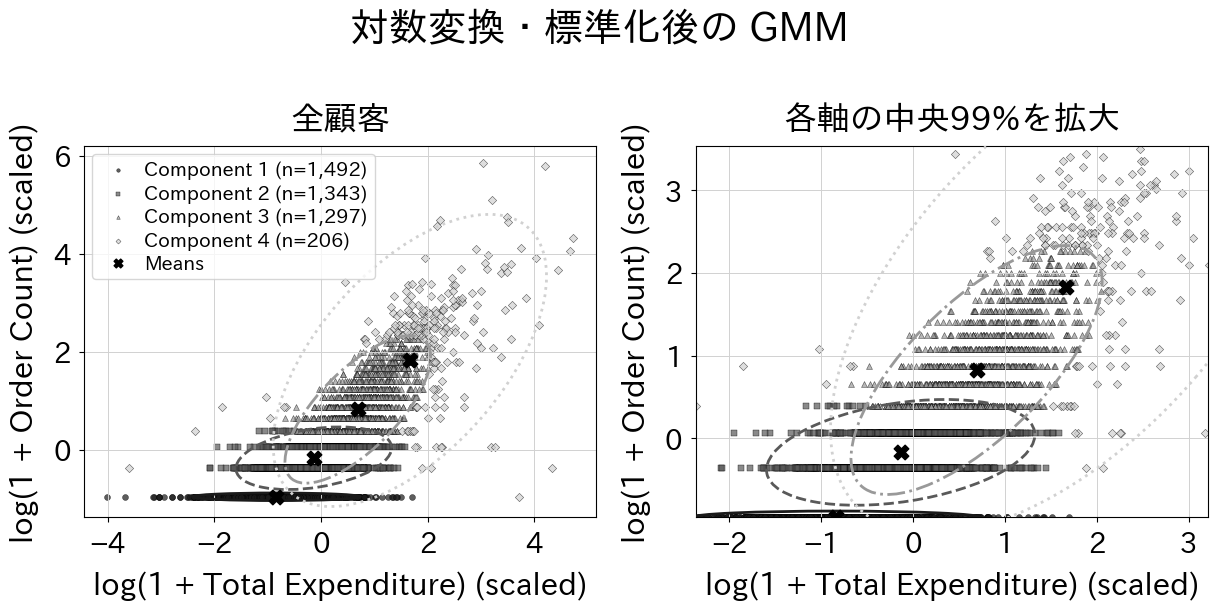

In [12]:
def add_confidence_ellipse(ax, mean, covariance, style, linestyle):
    eigenvalues, eigenvectors = np.linalg.eigh(covariance)
    order = eigenvalues.argsort()[::-1]
    eigenvalues = eigenvalues[order]
    eigenvectors = eigenvectors[:, order]
    angle = np.degrees(np.arctan2(eigenvectors[1, 0], eigenvectors[0, 0]))
    width, height = 2 * np.sqrt(5.991 * eigenvalues)
    ellipse = Ellipse(
        xy=mean,
        width=width,
        height=height,
        angle=angle,
        facecolor="none",
        edgecolor=style["color"],
        linewidth=2.0,
        linestyle=linestyle,
        zorder=4,
    )
    ax.add_patch(ellipse)


central_limits = np.quantile(X, [0.005, 0.995], axis=0)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 6.2))

for panel, (ax, title) in enumerate(
    zip(axes, ["全顧客", "各軸の中央99%を拡大"])
):
    for k in range(4):
        style = CLUSTER_STYLES[k]
        ax.scatter(
            X[labels_gmm == k, 0],
            X[labels_gmm == k, 1],
            color=style["color"],
            marker=style["marker"],
            edgecolors=MONO_BLACK,
            linewidths=0.35,
            alpha=0.70,
            s=18,
            label=f"Component {k + 1} (n={(labels_gmm == k).sum():,})",
        )
        add_confidence_ellipse(
            ax,
            centers_gmm[k],
            gmm_covariances[k],
            style,
            ["-", "--", "-.", ":"][k],
        )
    ax.scatter(
        centers_gmm[:, 0],
        centers_gmm[:, 1],
        color=MONO_BLACK,
        marker="X",
        s=110,
        label="Means",
        zorder=5,
    )
    if panel == 1:
        ax.set_xlim(*central_limits[:, 0])
        ax.set_ylim(*central_limits[:, 1])
    ax.set_xlabel(
        "log(1 + Total Expenditure) (scaled)", fontsize=22, labelpad=10
    )
    ax.set_ylabel("log(1 + Order Count) (scaled)", fontsize=22, labelpad=10)
    ax.set_title(title, fontsize=24, pad=12)
    ax.tick_params(axis="both", labelsize=20, pad=6)
    ax.grid(True, color=MONO_LIGHT, linewidth=0.7)

axes[0].legend(
    fontsize=14,
    loc="upper left",
    frameon=True,
    markerscale=0.6,
    borderpad=0.35,
    labelspacing=0.25,
    handletextpad=0.35,
    borderaxespad=0.4,
)
fig.suptitle("対数変換・標準化後の GMM", fontsize=28)
fig.tight_layout(rect=[0, 0, 1, 0.94], pad=1.2, w_pad=1.8)
plt.show()

## 第2章、第4節、第1項のコード

### Component 1 と Component 2 の詳細

全体図では重なって見えにくい Component 1 と Component 2 を拡大して可視化する。注目している成分以外の顧客は中間グレーで描くが、拡大範囲内にない点は表示されない。ジッターとは、同じ座標に重なる点を見分けやすくするため、描画時だけ各点の位置をランダムにわずかにずらす方法である。本図では横軸と縦軸の両方に微小なジッターを加えるため、注文回数が同じ顧客も上下にばらついて見えるが、GMM の学習にはジッターを加える前の値を用いる。

#### 処理内容

1. **対象とする成分の抽出と軸範囲の計算**
   各成分のデータ範囲に余白を加えて軸範囲を設定する。

2. **ジッターの付与**
   密集した点を見やすくするため、表示用にだけ横方向・縦方向へごく小さな乱数を加える。上下のばらつきは実際の注文回数の差を表すものではない。

3. **拡大図の描画**


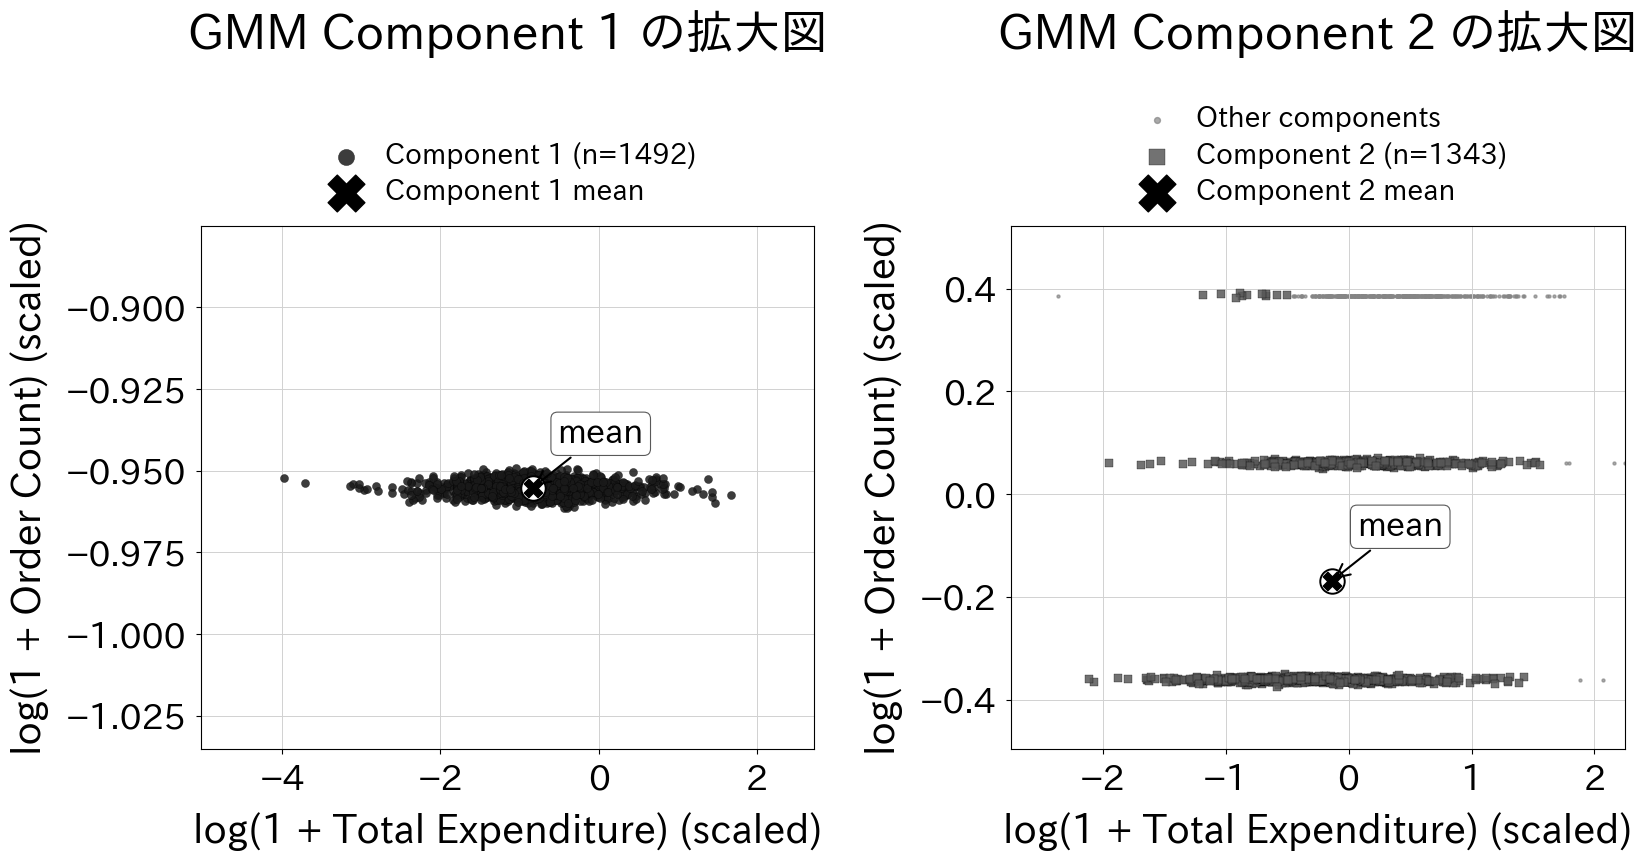

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 9.5))
rng = np.random.default_rng(42)

for ax, cluster_id in zip(axes, [0, 1]):
    target_mask = labels_gmm == cluster_id
    other_mask = ~target_mask

    x_target = X[target_mask, 0]
    y_target = X[target_mask, 1]

    x_margin = max((x_target.max() - x_target.min()) * 0.18, 0.03)
    y_margin = max((y_target.max() - y_target.min()) * 0.18, 0.08)

    # 密集している点を見やすくするため、表示用にだけ微小なジッターを加える。
    x_jitter = x_target + rng.normal(0, x_margin * 0.025, target_mask.sum())
    y_jitter = y_target + rng.normal(0, y_margin * 0.025, target_mask.sum())

    # Component 1 の拡大範囲には他成分の点がないため、右図だけ背景として描く。
    if cluster_id != 0:
        ax.scatter(
            X[other_mask, 0],
            X[other_mask, 1],
            color="0.52",
            marker=".",
            alpha=0.70,
            s=18,
            label="Other components",
        )
    ax.scatter(
        x_jitter,
        y_jitter,
        color=CLUSTER_STYLES[cluster_id]["color"],
        marker=CLUSTER_STYLES[cluster_id]["marker"],
        alpha=0.85,
        s=34,
        edgecolors="black",
        linewidths=0.25,
        label=f"Component {cluster_id + 1} (n={target_mask.sum()})",
        zorder=3,
    )
    ax.scatter(
        centers_gmm[cluster_id, 0],
        centers_gmm[cluster_id, 1],
        facecolors="white",
        edgecolors=MONO_BLACK,
        marker="o",
        s=310,
        linewidths=1.4,
        zorder=4,
    )
    ax.scatter(
        centers_gmm[cluster_id, 0],
        centers_gmm[cluster_id, 1],
        color=MONO_BLACK,
        marker="X",
        s=175,
        label=f"Component {cluster_id + 1} mean",
        zorder=5,
    )
    ax.annotate(
        "mean",
        xy=(centers_gmm[cluster_id, 0], centers_gmm[cluster_id, 1]),
        xytext=(18, 28),
        textcoords="offset points",
        fontsize=24,
        fontweight="bold",
        ha="left",
        va="bottom",
        arrowprops={"arrowstyle": "->", "color": MONO_BLACK, "linewidth": 1.5},
        bbox={
            "boxstyle": "round,pad=0.2",
            "facecolor": "white",
            "edgecolor": "0.35",
            "linewidth": 0.8,
        },
        zorder=6,
    )

    ax.set_xlim(x_target.min() - x_margin, x_target.max() + x_margin)
    ax.set_ylim(y_target.min() - y_margin, y_target.max() + y_margin)
    ax.set_xlabel(
        "log(1 + Total Expenditure) (scaled)", fontsize=28, labelpad=12
    )
    ax.set_ylabel("log(1 + Order Count) (scaled)", fontsize=28, labelpad=12)
    ax.set_title(
        f"GMM Component {cluster_id + 1} の拡大図",
        fontsize=34,
        y=1.34,
        pad=0,
    )
    ax.tick_params(labelsize=25, pad=7)
    ax.legend(
        fontsize=20,
        loc="lower center",
        bbox_to_anchor=(0.5, 1.02),
        ncol=1,
        frameon=False,
        borderaxespad=0.0,
        labelspacing=0.35,
        handletextpad=0.4,
        markerscale=2.0,
    )
    ax.grid(True, color=MONO_LIGHT, linewidth=0.7)

fig.subplots_adjust(left=0.09, right=0.98, bottom=0.13, top=0.68, wspace=0.32)
plt.show()

## 第2章、第4節、第2項のコード

### scikit-learn による所属確率の取得

前項で学習した GMM の `predict_proba()` 出力を、左下から右上へ並ぶ Component 1〜4 の順で確認する。

#### 処理内容

1. **所属確率の利用**
   前項で計算し、成分順を並べ替えた $(N \times K)$ の確率行列 `proba` を使う。

2. **結果の確認**
   先頭 5 行を指数形式で表示し、確率の分布を確認する。


In [14]:
# 各行が顧客、各列が Component 1〜4 に対応
print(
    np.array2string(proba[:5], formatter={"float_kind": lambda x: f"{x:.2e}"})
)

[[1.38e-04 3.83e-10 4.23e-21 1.00e+00]
 [0.00e+00 2.81e-05 8.80e-01 1.20e-01]
 [0.00e+00 1.72e-01 7.90e-01 3.71e-02]
 [9.94e-01 8.44e-04 2.45e-04 4.59e-03]
 [9.97e-01 1.28e-03 1.06e-03 1.81e-04]]


## 第2章、第4節、第2項のコード

### 所属確率を DataFrame にまとめる

所属確率を顧客情報・標準化した特徴量と結合した DataFrame を作成し、各顧客でもっとも高い所属確率と分類の曖昧さ（uncertainty）を合わせて計算する。

#### 処理内容

1. **所属確率を DataFrame にまとめる**
   `proba` 行列を Polars DataFrame に変換し、列名を `component_k_probability` とする。

2. **DataFrame の結合**
   顧客情報・標準化した特徴量・所属確率を `pl.concat()` で列方向に結合する。

3. **もっとも高い所属確率と分類の曖昧さの追加**
   `np.argmax` でもっとも所属確率が高い成分、`np.max` でその確率、`1 - max_probability` で分類の曖昧さを計算する。

4. **先頭データの確認**
   `probability_result[...].head()` で先頭行を表示する。


In [15]:
# 所属確率を DataFrame として整理
prob_df = pl.DataFrame(
    proba,
    schema=[f"component_{k + 1}_probability" for k in range(proba.shape[1])],
)

# 顧客情報・標準化した特徴量・所属確率を結合
probability_result = (
    pl.concat(
        [
            df.select(["CustomerID", "total_expenditure", "order_count"]),
            df_scaled,
            prob_df,
        ],
        how="horizontal",
    )
    .with_columns(
        pl.Series("gmm_component", gmm_component),
        pl.Series("max_probability", max_probability),
    )
    .with_columns(pl.Series("uncertainty", uncertainty))
)

probability_columns = [
    "CustomerID",
    "component_1_probability",
    "component_2_probability",
    "component_3_probability",
    "component_4_probability",
    "gmm_component",
    "max_probability",
    "uncertainty",
]
probability_head = probability_result.select(probability_columns).head()
probability_head

CustomerID,component_1_probability,component_2_probability,component_3_probability,component_4_probability,gmm_component,max_probability,uncertainty
i64,f64,f64,f64,f64,i64,f64,f64
12346,0.000138,3.8278e-10,4.2317e-21,0.999862,4,0.999862,0.000138
12347,0.0,0.000028,0.879762,0.12021,3,0.879762,0.120238
12348,0.0,0.172452,0.790442,0.037106,3,0.790442,0.209558
12349,0.994317,0.000844,0.000245,0.004593,1,0.994317,0.005683
12350,0.997478,0.001281,0.00106,0.000181,1,0.997478,0.002522


## 第2章、第4節、第2項のコード

### 成分ごとの所属確率の散布図と、もっとも高い所属確率の分布

各顧客がそれぞれの成分に属する確率を灰色の濃淡で表した散布図を 4 成分分並べて描画する。点が濃いほど所属確率が高い。さらに、割り当て先がどの程度明確かを確認するため、もっとも高い所属確率の分布を描く。

#### 処理内容

1. **2×2 に並べた 4 つのグラフの作成**
   `plt.subplots(2, 2, sharex=True, sharey=True)` で軸を共有する 4 つのグラフを用意する。

2. **確率を色で表した散布図**
   各成分の確率列を `c` 引数に渡し、低い確率を薄い灰色、高い確率を黒で表す。

3. **濃淡の目盛り**
   各グラフに濃淡の目盛りを追加する。

4. **もっとも高い所属確率の分布**
   全顧客でもっとも高い所属確率を表示し、0.8 の判断目安と中央値を重ねる。


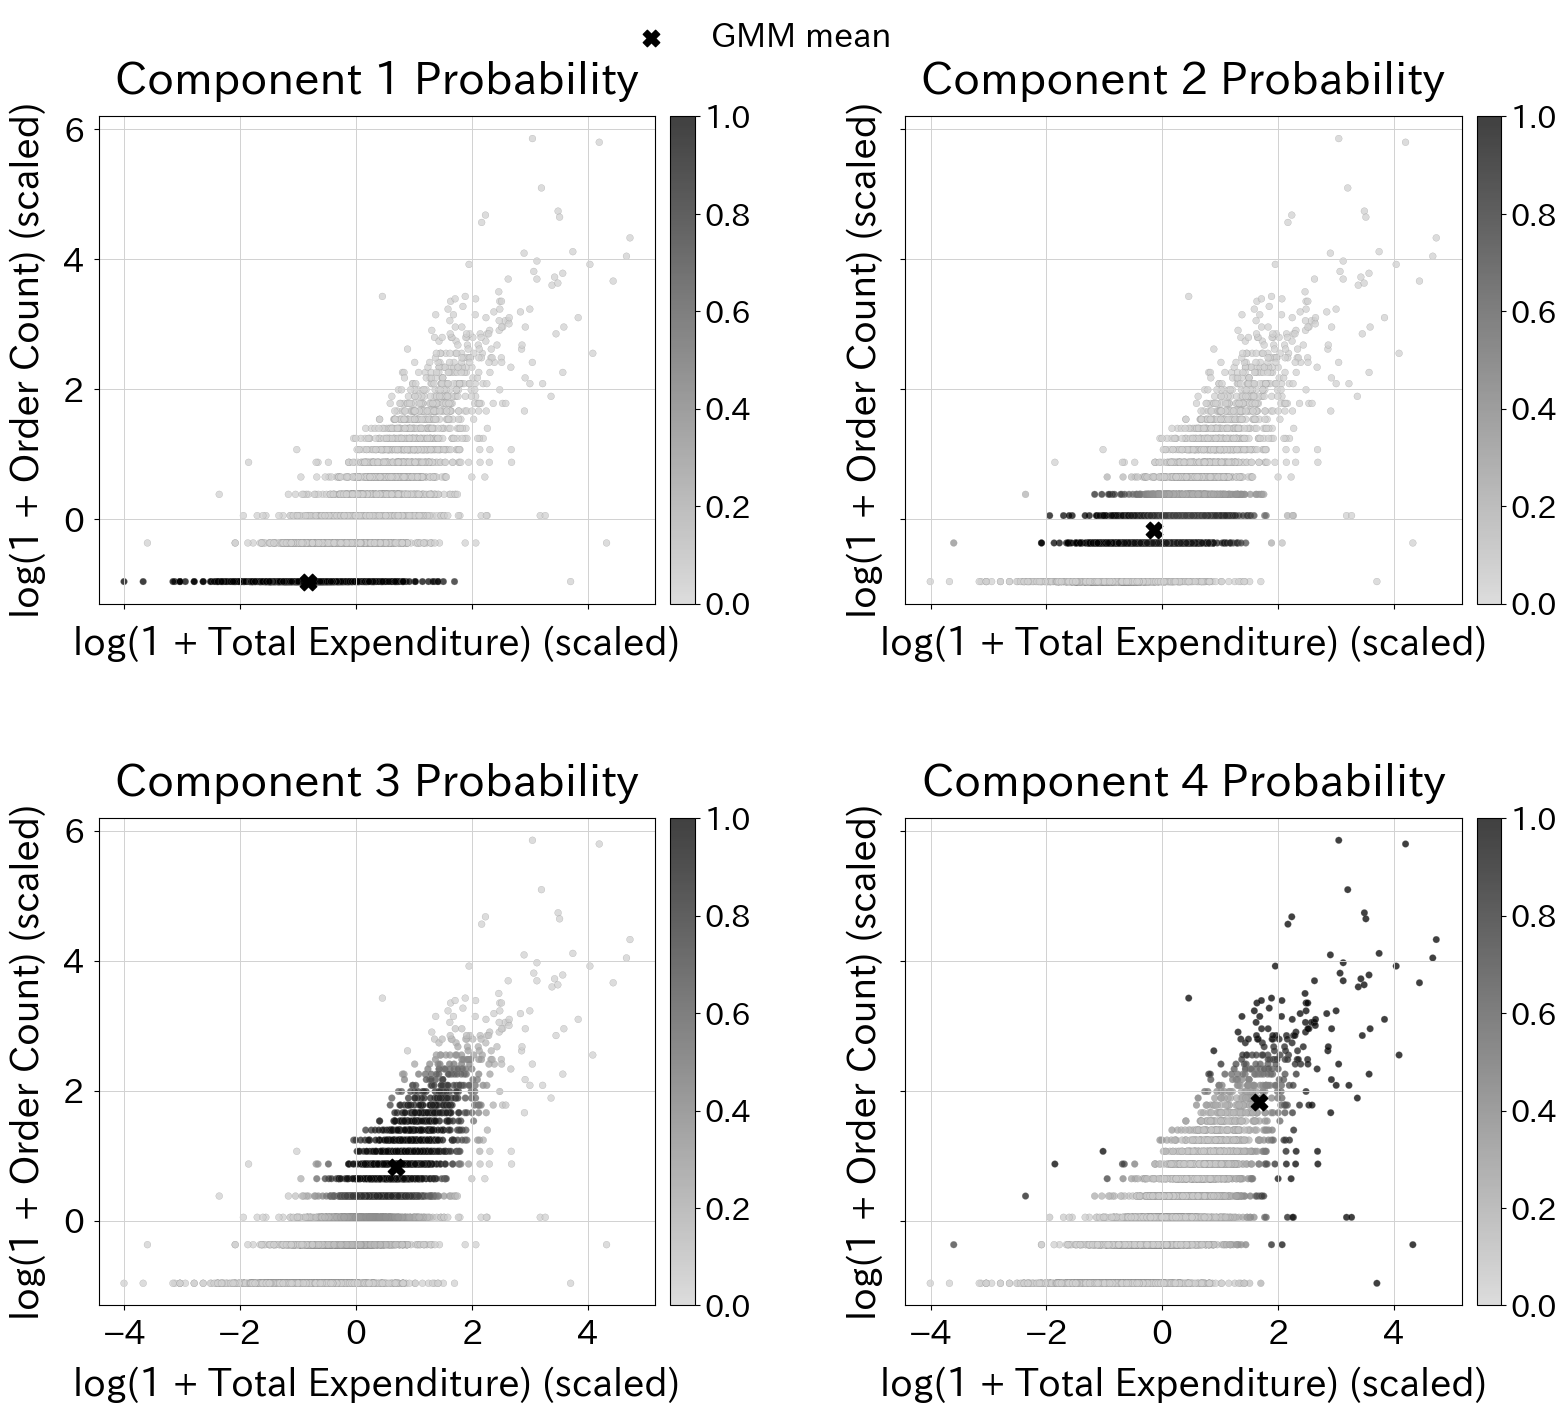

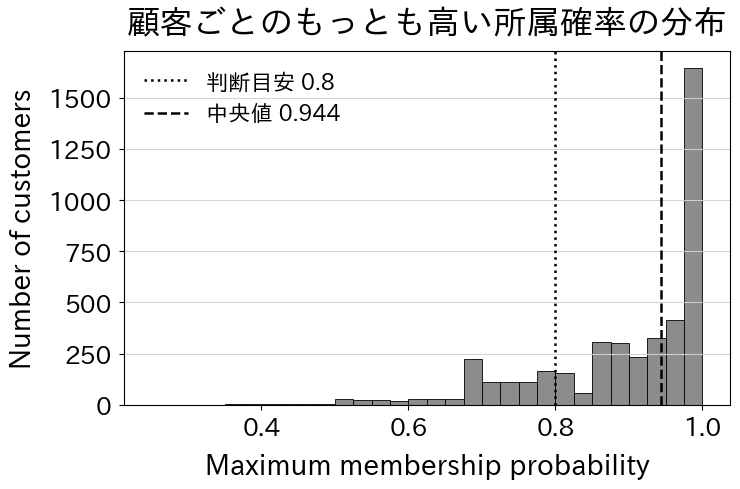

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(16, 14.5), sharex=True, sharey=True)
axes = axes.ravel()

for k, ax in enumerate(axes):
    prob_col = f"component_{k + 1}_probability"
    sc = ax.scatter(
        probability_result["total_expenditure_log_scaled"].to_numpy(),
        probability_result["order_count_log_scaled"].to_numpy(),
        c=probability_result[prob_col].to_numpy(),
        cmap=PROBABILITY_CMAP,
        vmin=0,
        vmax=1,
        alpha=0.75,
        s=24,
        edgecolors=MONO_MID,
        linewidths=0.2,
    )
    mean_handle = ax.scatter(
        centers_gmm[k, 0],
        centers_gmm[k, 1],
        color=MONO_BLACK,
        marker="X",
        s=140,
        label="GMM mean",
    )
    ax.set_title(f"Component {k + 1} Probability", fontsize=32, pad=16)
    ax.set_xlabel(
        "log(1 + Total Expenditure) (scaled)", fontsize=27, labelpad=12
    )
    ax.set_ylabel("log(1 + Order Count) (scaled)", fontsize=27, labelpad=12)
    ax.tick_params(labelsize=24, pad=7)
    ax.grid(True, color=MONO_LIGHT, linewidth=0.7)
    colorbar = fig.colorbar(sc, ax=ax, fraction=0.05, pad=0.025)
    colorbar.ax.tick_params(labelsize=22)

fig.legend(
    [mean_handle],
    ["GMM mean"],
    loc="upper center",
    bbox_to_anchor=(0.5, 0.985),
    fontsize=24,
    frameon=False,
)
fig.subplots_adjust(
    left=0.09,
    right=0.97,
    bottom=0.08,
    top=0.90,
    wspace=0.34,
    hspace=0.44,
)
plt.show()

fig, ax = plt.subplots(figsize=(7.5, 5.0))
ax.hist(
    max_probability,
    bins=np.linspace(0.25, 1.0, 31),
    color=MONO_MID,
    edgecolor=MONO_BLACK,
    linewidth=0.6,
)
ax.axvline(
    0.8, color=MONO_BLACK, linestyle=":", linewidth=1.8, label="判断目安 0.8"
)
median_probability = float(np.median(max_probability))
ax.axvline(
    median_probability,
    color=MONO_BLACK,
    linestyle="--",
    linewidth=1.8,
    label=f"中央値 {median_probability:.3f}",
)
ax.set_xlabel("Maximum membership probability", fontsize=20, labelpad=9)
ax.set_ylabel("Number of customers", fontsize=20, labelpad=9)
ax.set_title("顧客ごとのもっとも高い所属確率の分布", fontsize=24, pad=13)
ax.tick_params(axis="both", labelsize=18, pad=5)
ax.grid(True, axis="y", color=MONO_LIGHT, linewidth=0.7)
ax.legend(frameon=False, fontsize=16)
fig.tight_layout()
plt.show()